# Residential Property Price Prediction

## Project Outline

We structured the notebook around the five project requirements:

1. Build a Data Quality Report from the raw training set.
2. Apply a Data Quality Plan and produce a clean modelling dataset.
3. Explore feature relationships relevant to price.
4. Create new engineered features, including location-based CSO features.
5. Train and evaluate prediction models using time series split.

In [1]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

## 1. Data Quality Report

The initial inspection of the training data identified the main structural properties of the dataset:

- 54,000 rows and 9 original features.
- `Price (€)` is the target and is strongly right-skewed with extreme upper-tail values.
- `Eircode` has high missingness and extremely high cardinality.
- `Property Size Description` has very high missingness.
- `Description of Property` contains English and Irish labels for the same concept.
- `Address` is messy free text and unsuitable as-is for direct modelling.

We start by reproducing the key inspection and basic cleaning steps on the raw training file.

In [2]:
train_raw = pd.read_csv('../data/ppr-group-25200353-train.csv')
print(train_raw.shape)
display(train_raw.head(3))
train_raw.info()

(54000, 9)


,Date of Sale (dd/mm/yyyy),Address,County,Eircode,Price (€),Not Full Market Price,VAT Exclusive,Description of Property,Property Size Description
0,29/02/2016,"APT 14, RUSSELL COURT, FELTRIM RD",Dublin,NaN,"€118,487.00",No,No,Second-Hand Dwelling house /Apartment,NaN
1,08/07/2016,"19 PARK VILLAS, DEMESNE RD, DUNDALK",Louth,NaN,"€222,000.00",No,No,Second-Hand Dwelling house /Apartment,NaN
2,15/04/2016,"No 2 The Grove, Cahereen Heights, Castleisland",Kerry,NaN,"€123,348.00",No,Yes,New Dwelling house /Apartment,greater than 125 sq metres


<class 'pandas.DataFrame'>
RangeIndex: 54000 entries, 0 to 53999
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   Date of Sale (dd/mm/yyyy)  54000 non-null  str  
 1   Address                    54000 non-null  str  
 2   County                     54000 non-null  str  
 3   Eircode                    16897 non-null  str  
 4   Price (€)                  54000 non-null  str  
 5   Not Full Market Price      54000 non-null  str  
 6   VAT Exclusive              54000 non-null  str  
 7   Description of Property    54000 non-null  str  
 8   Property Size Description  2799 non-null   str  
dtypes: str(9)
memory usage: 3.7 MB


In [3]:
train_dqr = train_raw.copy()

train_dqr["Price (€)"] = (
    train_dqr["Price (€)"]
    .astype(str)
    .str.replace("€", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)
train_dqr["Price (€)"] = pd.to_numeric(train_dqr["Price (€)"], errors="coerce")
train_dqr["Date of Sale (dd/mm/yyyy)"] = pd.to_datetime(
    train_dqr["Date of Sale (dd/mm/yyyy)"], dayfirst=True, errors="coerce"
)

categorical_cols = [
    "County",
    "Not Full Market Price",
    "VAT Exclusive",
    "Description of Property",
    "Property Size Description",
    "Eircode",
]
for col in categorical_cols:
    train_dqr[col] = train_dqr[col].astype("category")

duplicate_rows = train_dqr.duplicated().sum()

print(f"Duplicate rows: {duplicate_rows}")
print(train_dqr.dtypes)

Duplicate rows: 8
Date of Sale (dd/mm/yyyy)    datetime64[us]
Address                                 str
County                             category
Eircode                            category
Price (€)                           float64
Not Full Market Price              category
VAT Exclusive                      category
Description of Property            category
Property Size Description          category
dtype: object


In [4]:
missing_summary = train_dqr.isna().sum().to_frame("missing_count")
missing_summary["missing_pct"] = (missing_summary["missing_count"] / len(train_dqr) * 100).round(2)
display(missing_summary.sort_values("missing_pct", ascending=False))

,missing_count,missing_pct
Property Size Description,51201,94.82
Eircode,37103,68.71
Date of Sale (dd/mm/yyyy),0,0.00
Address,0,0.00
County,0,0.00
Price (€),0,0.00
Not Full Market Price,0,0.00
VAT Exclusive,0,0.00
Description of Property,0,0.00


In [5]:
duplicate_columns = train_dqr.columns[train_dqr.columns.duplicated()].tolist()
constant_columns = [
    col for col in train_dqr.columns
    if train_dqr[col].nunique(dropna=False) <= 1
]

print("Duplicate columns:", duplicate_columns if duplicate_columns else "None")
print("Constant columns:", constant_columns if constant_columns else "None")

Duplicate columns: None
Constant columns: None


In [6]:
before = len(train_dqr)
train_dqr = train_dqr.drop_duplicates().reset_index(drop=True)
after = len(train_dqr)

print(f"Removed {before - after} duplicate rows")

Removed 8 duplicate rows


In [7]:
train_dqr.to_csv("../data/ppr-group-25200353-train-cleaned.csv", index=False)
print("Saved cleaned training file for DQR.")

Saved cleaned training file for DQR.


In [8]:
def build_numeric_dqr(df, columns):
    results = []
    total_count = len(df)

    for col in columns:
        series = df[col]
        results.append([
            col,
            total_count,
            100 * series.isna().sum() / total_count,
            series.nunique(dropna=True),
            series.min(),
            series.quantile(0.25),
            series.mean(),
            series.median(),
            series.quantile(0.75),
            series.max(),
            series.std(),
        ])

    return pd.DataFrame(results, columns=[
        "Feature",
        "Count",
        "Missing %",
        "Cardinality",
        "Minimum",
        "1st Quartile",
        "Mean",
        "Median",
        "3rd Quartile",
        "Maximum",
        "Standard Dev.",
    ])


def build_categorical_dqr(df, columns):
    results = []
    total_count = len(df)

    for col in columns:
        series = df[col]
        value_counts = series.value_counts(dropna=True)

        if len(value_counts) > 0:
            mode = value_counts.index[0]
            mode_freq = value_counts.iloc[0]
            mode_pct = 100 * mode_freq / total_count
        else:
            mode = np.nan
            mode_freq = 0
            mode_pct = 0

        if len(value_counts) > 1:
            second_mode = value_counts.index[1]
            second_mode_freq = value_counts.iloc[1]
            second_mode_pct = 100 * second_mode_freq / total_count
        else:
            second_mode = np.nan
            second_mode_freq = 0
            second_mode_pct = 0

        results.append([
            col,
            total_count,
            100 * series.isna().sum() / total_count,
            series.nunique(dropna=True),
            mode,
            mode_freq,
            mode_pct,
            second_mode,
            second_mode_freq,
            second_mode_pct,
        ])

    return pd.DataFrame(results, columns=[
        "Feature",
        "Count",
        "Missing %",
        "Cardinality",
        "Mode",
        "Mode Freq.",
        "Mode %",
        "2nd Mode",
        "2nd Mode Freq.",
        "2nd Mode %",
    ])

In [9]:
numeric_columns = train_dqr.select_dtypes(['int64', 'float64']).columns
category_columns = train_dqr.select_dtypes(['category']).columns

df_numeric_dqr = build_numeric_dqr(train_dqr, numeric_columns)
display(df_numeric_dqr)

df_categorical_dqr = build_categorical_dqr(train_dqr, category_columns)
display(df_categorical_dqr)

,Feature,Count,Missing %,Cardinality,Minimum,1st Quartile,Mean,Median,3rd Quartile,Maximum,Standard Dev.
0,Price (€),53992,0.0,6788,5260.0,158590.33,327045.85816,252000.0,365000.0,1.358598e+08,1.108129e+06


,Feature,Count,Missing %,Cardinality,Mode,Mode Freq.,Mode %,2nd Mode,2nd Mode Freq.,2nd Mode %
0,County,53992,0.000000,26,Dublin,16573,30.695288,Cork,6038,11.183138
1,Eircode,53992,68.712031,16840,D08X5T9,3,0.005556,D24W9NN,3,0.005556
2,Not Full Market Price,53992,0.000000,2,No,51143,94.723292,Yes,2849,5.276708
3,VAT Exclusive,53992,0.000000,2,No,44523,82.462217,Yes,9469,17.537783
4,Description of Property,53992,0.000000,3,Second-Hand Dwelling house /Apartment,44359,82.158468,New Dwelling house /Apartment,9630,17.835976
5,Property Size Description,53992,94.815899,4,greater than or equal to 38 sq metres and less...,2088,3.867240,greater than or equal to 125 sq metres,493,0.913098


In [10]:
# Other feature types
date_col = "Date of Sale (dd/mm/yyyy)"
print("Date min:", train_dqr[date_col].min())
print("Date max:", train_dqr[date_col].max())
print("Missing dates:", train_dqr[date_col].isna().sum())

address_col = "Address"
print("Missing addresses:", train_dqr[address_col].isna().sum())
print("Duplicate addresses:", train_dqr[address_col].duplicated().sum())
print("Unique addresses:", train_dqr[address_col].nunique())

Date min: 2016-01-04 00:00:00
Date max: 2024-12-31 00:00:00
Missing dates: 0
Missing addresses: 0
Duplicate addresses: 699
Unique addresses: 53293


## Visualising Continuous Features: Histogram/Boxplots

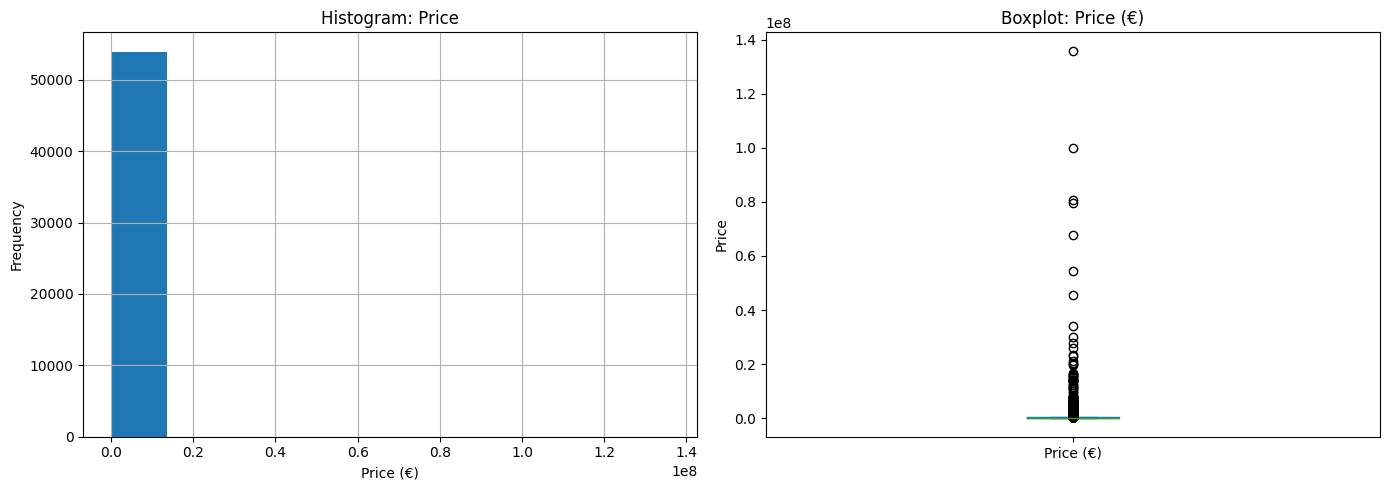

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
train_dqr['Price (€)'].hist(ax=axes[0])
axes[0].set_title('Histogram: Price')
axes[0].set_xlabel('Price (€)')
axes[0].set_ylabel('Frequency')

# Boxplot
train_dqr['Price (€)'].plot(kind='box', ax=axes[1])
axes[1].set_title('Boxplot: Price (€)')
axes[1].set_ylabel('Price')

plt.tight_layout()
plt.show()

As seen above, the price feature is heavily right-skewed. The graph below shows up to the 99th percentile.

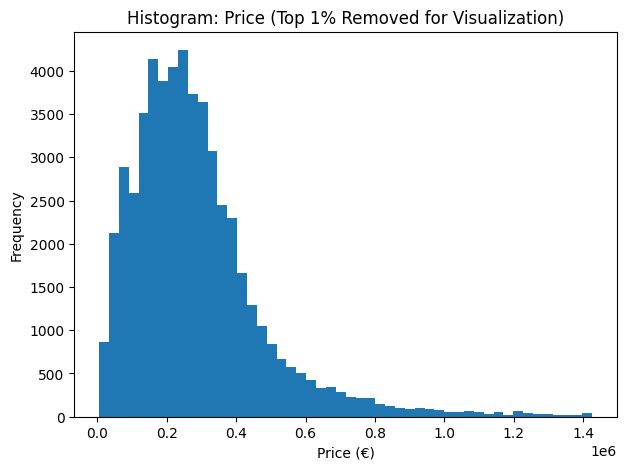

In [12]:
upper_limit = train_dqr['Price (€)'].quantile(0.99)

filtered_prices = train_dqr[train_dqr['Price (€)'] <= upper_limit]['Price (€)']

plt.figure(figsize=(7,5))
plt.hist(filtered_prices, bins=50)
plt.title('Histogram: Price (Top 1% Removed for Visualization)')
plt.xlabel('Price (€)')
plt.ylabel('Frequency')
plt.show()

## Visualizing Categorical Features: Bar Plots

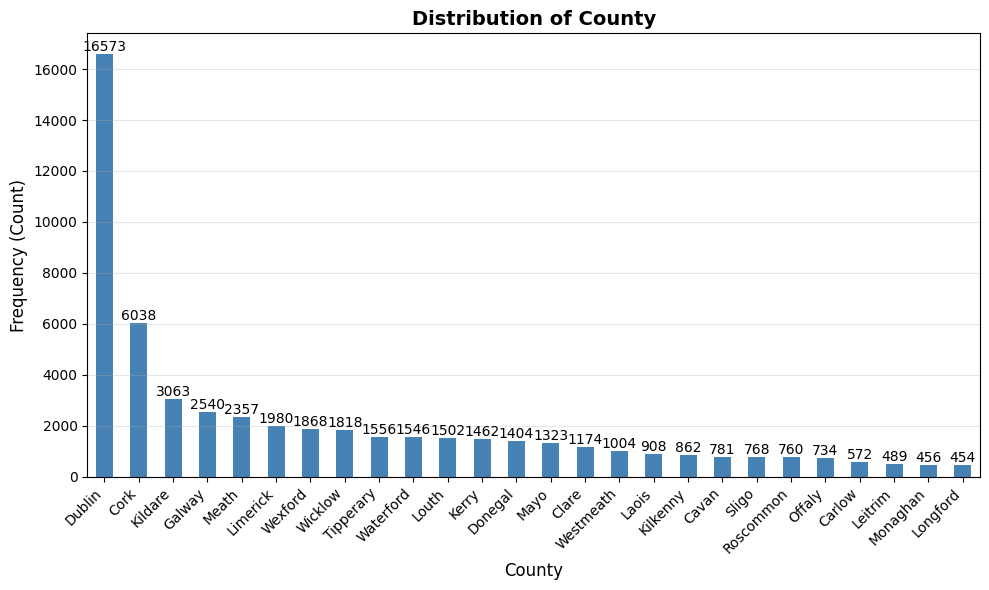

In [13]:
plt.figure(figsize=(10, 6))
ax = train_dqr['County'].value_counts(dropna=False).plot(kind='bar', color='steelblue')
plt.title('Distribution of County', fontsize=14, fontweight='bold')
plt.xlabel('County', fontsize=12)
plt.ylabel('Frequency (Count)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

# Add value labels on top of bars
for container in ax.containers:
    ax.bar_label(container, fmt='%d')

plt.tight_layout()
plt.show()

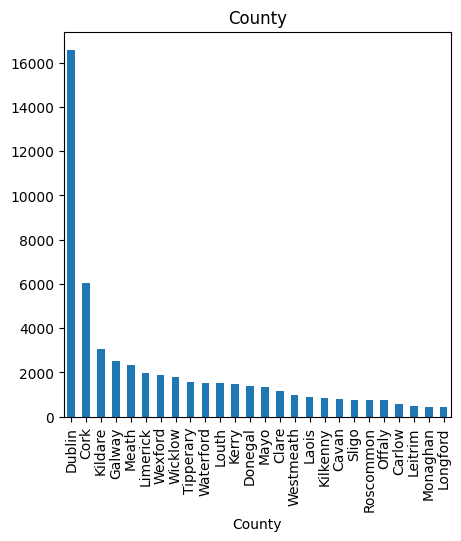

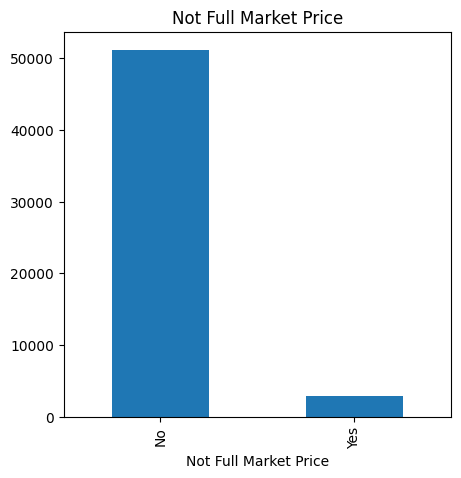

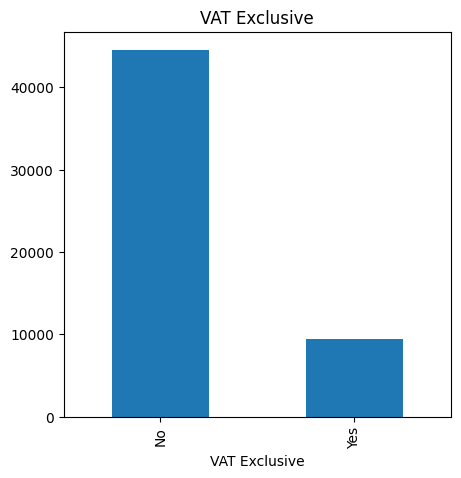

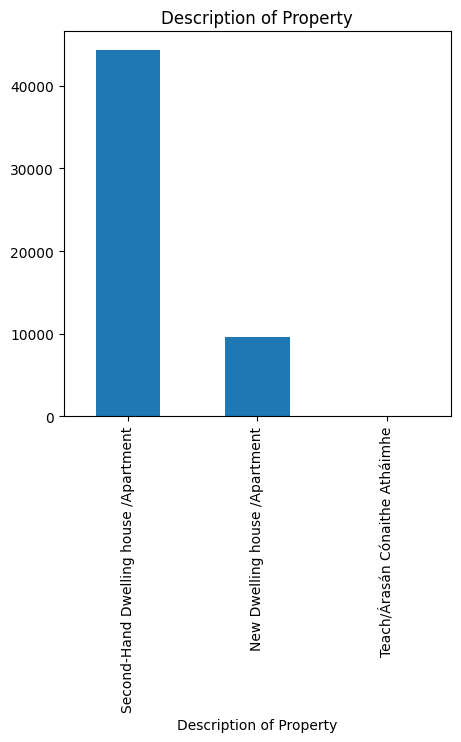

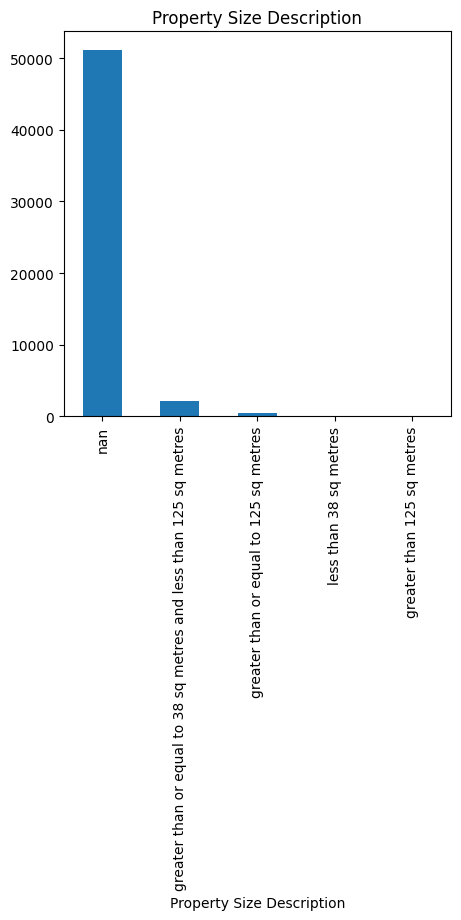

In [14]:
# Bar plots for categorical features
for col in category_columns:
    if col != 'Eircode':
        plt.figure(figsize=(5,5))
        train_dqr[col].value_counts(dropna=False).plot(kind='bar', title=col)
        plt.show()

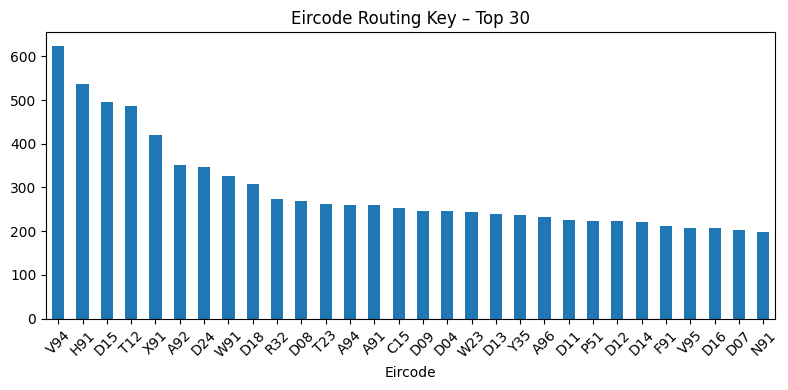

In [15]:
# Bar plot for most common Eircode Routing Key
eircode_routing = train_dqr['Eircode'].str[:3]
plt.figure(figsize=(8,4))

eircode_routing \
    .value_counts() \
    .head(30) \
    .plot(kind='bar')

plt.title("Eircode Routing Key – Top 30")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

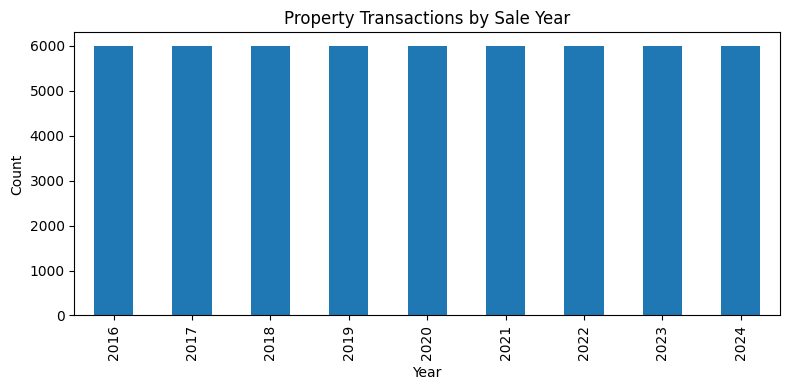

In [16]:
# Plot for date of sale
sales_by_year = train_dqr["Date of Sale (dd/mm/yyyy)"].dt.year.value_counts().sort_index()
plt.figure(figsize=(8,4))
sales_by_year.plot(kind="bar")
plt.title("Property Transactions by Sale Year")
plt.xlabel("Year")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

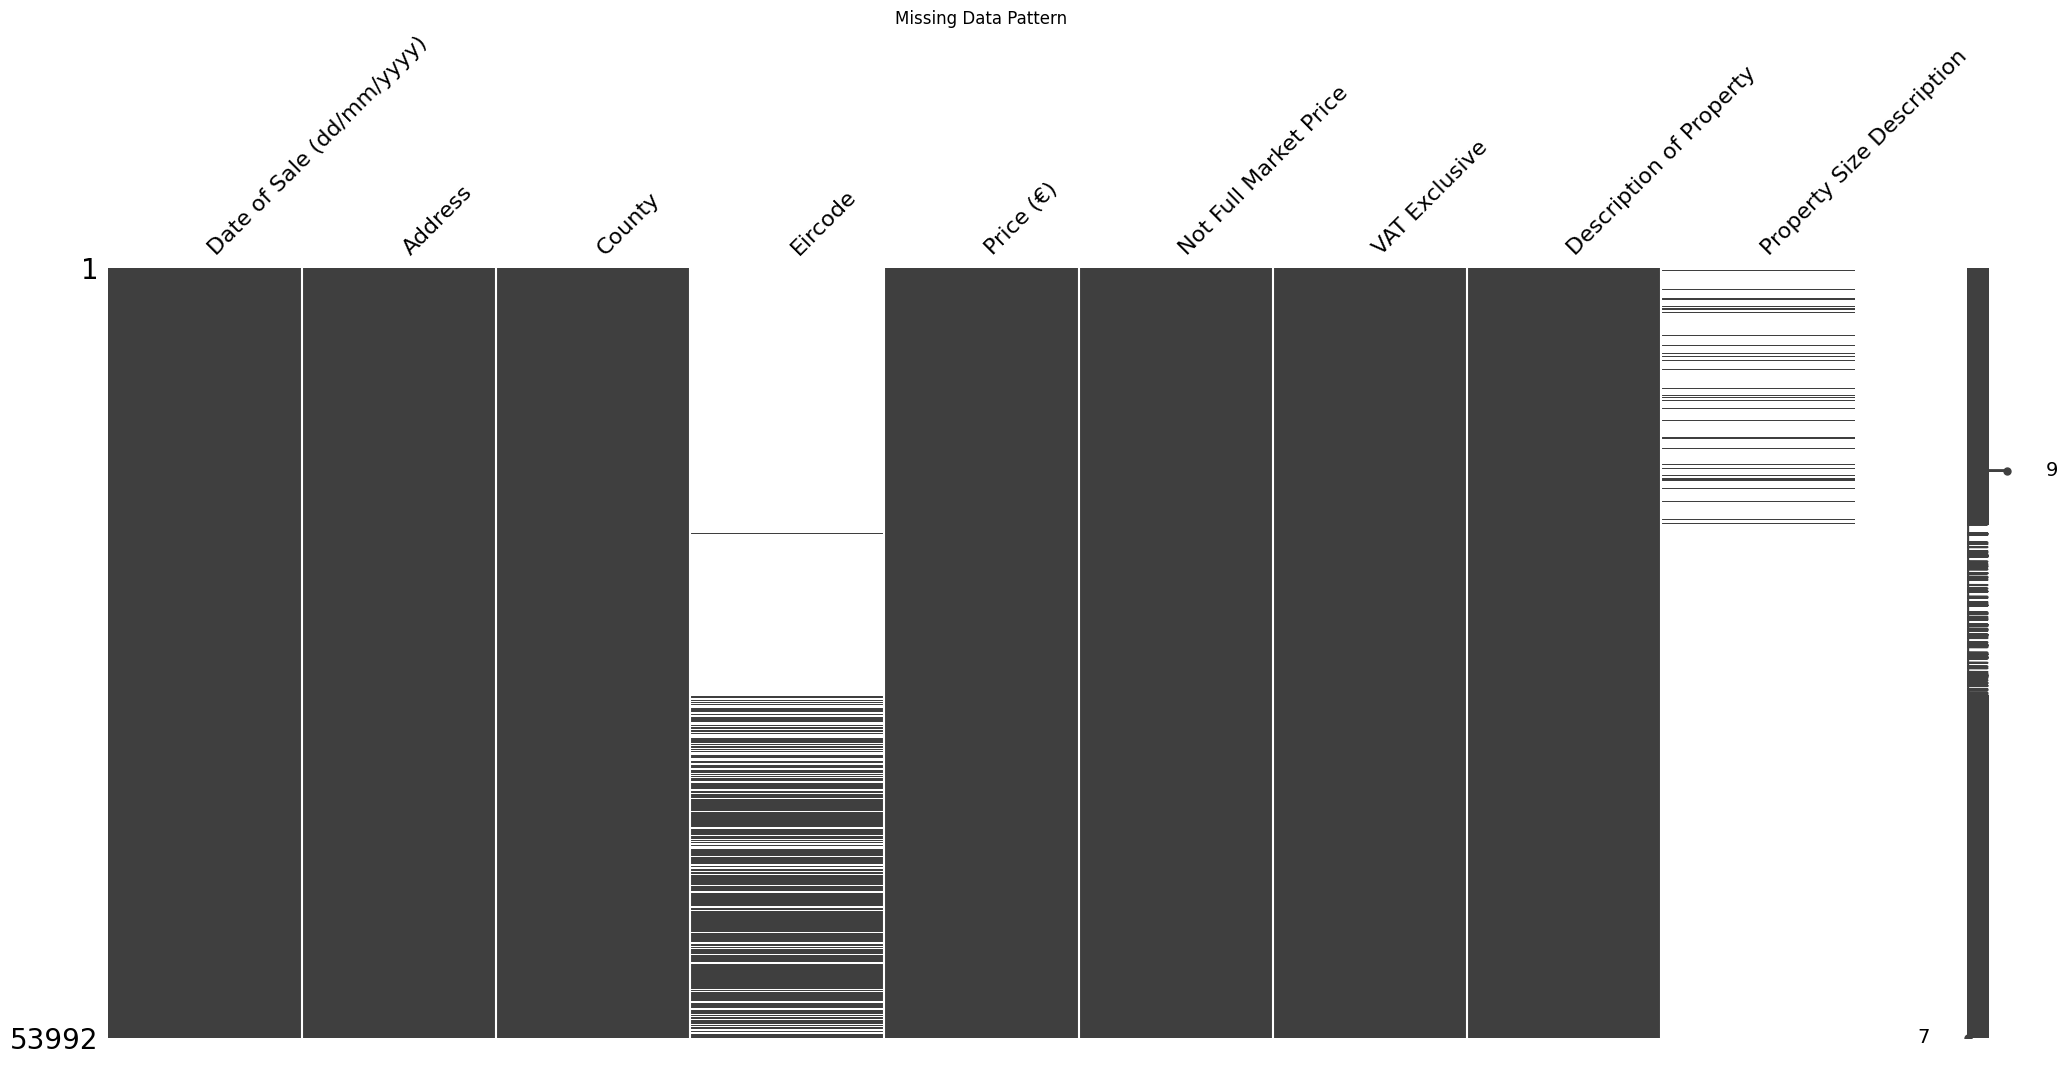

In [17]:
import missingno as msno
msno.matrix(train_dqr)

plt.title("Missing Data Pattern")
plt.show()

### DQR Summary

The inspection above supports the following observations and likely preprocessing decisions for the next stage:

- Exact duplicate rows were identified and removed.
- `Price (€)` is strongly right-skewed with extreme but likely valid upper-tail transactions; transformation or clamping may be considered later.
- `Eircode` has both high missingness and high cardinality, making it a weak candidate for modelling.
- `Property Size Description` is mostly missing and may need to be dropped or handled carefully.
- `Description of Property` contains inconsistent category labels and should be standardised.
- `Address` is unstructured free text and may be more useful for feature extraction than as a raw predictor.

----------------------------------------------------------------------------------------

## 2. Data Quality Plan

The decisions below define the preprocessing pipeline used for the project:

- `price`: cleaned to numeric and clamped at the 99th percentile.
- `eircode`: removed.
- `property size description`: removed.
- `description of property`: Irish labels translated to English.
- `address`: standardised for geocoding.
- binary flags: preserved and encoded later for modelling.
- dates: preserved and transformed into temporal features during feature engineering.

The next cell implements that plan as reusable code.

In [18]:
def standardise_address(row, address_col="address", county_col="county"):
    if pd.isna(row[address_col]):
        return None

    address = str(row[address_col]).upper().strip()
    county = str(row[county_col]).upper().strip()

    address = re.sub(r"^(?:APT|FLAT|UNIT|NO|NOS)\.?\s*\w+\s*-?\s*", "", address)
    address = re.sub(r"\b(\d+[A-Z]*)\s*(?:-|TO|/|&|AND)\s*\d+[A-Z]*\b", r"\1", address)
    address = re.sub(r"^(\d+[A-Z]*)\s+\d+(?:\s+\d+)*\s+", r"\1 ", address)
    address = re.sub(r"\s{2,}", " ", address)
    address = re.sub(r"^,\s*", "", address).strip()

    county_suffix = f"CO. {county}"
    if not address.endswith(county_suffix):
        address = f"{address}, {county_suffix}"

    return address


def clean_dataframe(df, upper_price_cap=None):
    cleaned = df.copy()

    cleaned["Price (€)"] = (
        cleaned["Price (€)"]
        .astype(str)
        .str.replace("€", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.strip()
    )
    cleaned["Price (€)"] = pd.to_numeric(cleaned["Price (€)"], errors="coerce")
    
    cleaned["Date of Sale (dd/mm/yyyy)"] = pd.to_datetime(
        cleaned["Date of Sale (dd/mm/yyyy)"], dayfirst=True, errors="coerce"
    )

    cleaned = cleaned.drop_duplicates().reset_index(drop=True)

    if upper_price_cap is None:
        upper_price_cap = cleaned["Price (€)"].quantile(0.99)

    cleaned["clamped_price"] = cleaned["Price (€)"].clip(upper=upper_price_cap)

    cleaned.loc[
        cleaned["Description of Property"] == "Teach/Árasán Cónaithe Atháimhe",
        "Description of Property",
    ] = "Second-Hand Dwelling house /Apartment"

    cleaned = cleaned.drop(columns=["Eircode", "Property Size Description"])
    
    cleaned = cleaned.rename(
        columns={
            "Date of Sale (dd/mm/yyyy)": "date_of_sale",
            "Address": "address",
            "County": "county",
            "Price (€)": "price",
            "Not Full Market Price": "not_full_market_price",
            "VAT Exclusive": "vat_exclusive",
            "Description of Property": "property_description",
        }
    )

    cleaned["address"] = cleaned.apply(standardise_address, axis=1)

    return cleaned, upper_price_cap

train_clean_final, upper_price_cap = clean_dataframe(train_raw)

print(f"Train shape: {train_clean_final.shape}")
print(f"Upper price cap learned from train: {upper_price_cap:,.0f}")
train_clean_final.head()

Train shape: (53992, 8)
Upper price cap learned from train: 1,426,515


,date_of_sale,address,county,price,not_full_market_price,vat_exclusive,property_description,clamped_price
0,2016-02-29,"RUSSELL COURT, FELTRIM RD, CO. DUBLIN",Dublin,118487.0,No,No,Second-Hand Dwelling house /Apartment,118487.0
1,2016-07-08,"19 PARK VILLAS, DEMESNE RD, DUNDALK, CO. LOUTH",Louth,222000.0,No,No,Second-Hand Dwelling house /Apartment,222000.0
2,2016-04-15,"THE GROVE, CAHEREEN HEIGHTS, CASTLEISLAND, CO....",Kerry,123348.0,No,Yes,New Dwelling house /Apartment,123348.0
3,2016-12-21,"BLOCK 6, WOODFORD, WHEATON HALL, CO. LOUTH",Louth,115000.0,No,No,Second-Hand Dwelling house /Apartment,115000.0
4,2016-10-11,"18 GERALDINE ST, DUBLIN 7, DUBLIN, CO. DUBLIN",Dublin,225500.0,No,No,Second-Hand Dwelling house /Apartment,225500.0


In [19]:
# Ensure no NaNs in final cleaned data
train_clean_final.isna().sum()

date_of_sale             0
address                  0
county                   0
price                    0
not_full_market_price    0
vat_exclusive            0
property_description     0
clamped_price            0
dtype: int64

In [20]:
train_clean_final.to_csv("../data/ppr-group-25200353-train-clean-final.csv", index=False)
print("Saved: ../data/ppr-group-25200353-train-clean-final.csv")

Saved: ../data/ppr-group-25200353-train-clean-final.csv


### Final Feature Decisions

| Feature | Final Type | Main Issue | Solution Applied |
| --- | --- | --- | --- |
| `date_of_sale` | Temporal | None | Kept and engineered into time features |
| `address` | Text | High-cardinality inconsistent free text | Standardised for geocoding, not used directly as model input |
| `county` | Categorical | None | Kept as geographic context |
| `price` | Continuous target | Heavy right skew and extreme upper tail | Cleaned to numeric and clamped at the 99th percentile for selected model variants |
| `not_full_market_price` | Binary categorical | None | Kept and binary encoded |
| `vat_exclusive` | Binary categorical | High overlap with `property_description` | Kept in cleaned data, excluded from final model feature set |
| `property_description` | Categorical | Mixed Irish/English labels | Translated to a consistent English encoding |
| `eircode` | Categorical | High missingness and high cardinality | Removed |
| `property_size_description` | Ordinal categorical | Extreme missingness | Removed |


`train_clean_final.csv` is the final non-geocoded modelling base table used before adding geographic context.

----------------------------------------------------------------------------------------

# 3. Exploring relationships between feature pairs.

Based on the Data Quality Report and initial exploratory analysis, a subset of features was selected for further investigation. Features were chosen based on their completeness, interpretability, and informed by domain knowledge. In particular, temporal features, geographic location, and property characteristics were identified as likely drivers of property price. These features were therefore examined in more detail using pairwise visualisations to assess their relationship with the target variable. 


## 3.1 Price over time

The relationship between property price and time was examined using the monthly median sale price. Monthly aggregation using the median was chosen to reduce the impact of extreme values and provide a clearer representation of underlying trends. The results show a clear upward trend in property prices over the period from 2016 to 2024. Median prices increased from approximately €170,000 in 2016 to over €330,000 in 2024, indicating substantial growth in the housing market. While some short-term fluctuations are visible, particularly around 2020–2021, the overall trend remains strongly positive. This suggests that time is an important factor influencing property prices, making temporal features potentially valuable predictors in later modelling stages.

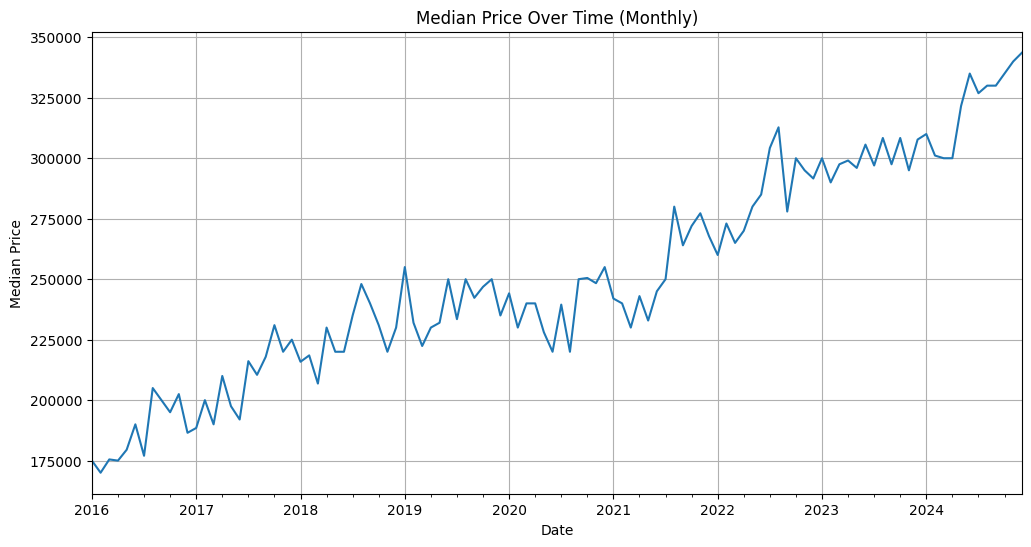

In [21]:
# Ensure sorted by date
train_clean_final = train_clean_final.sort_values('date_of_sale')

monthly_median = (
    train_clean_final.sort_values('date_of_sale')
      .set_index('date_of_sale')['price']
      .resample('ME')
      .median()
)

plt.figure(figsize=(12,6))
monthly_median.plot()

plt.title('Median Price Over Time (Monthly)')
plt.xlabel('Date')
plt.ylabel('Median Price')
plt.grid(True)
plt.show()

## 3.2 Price vs County

The relationship between property price and county was examined using both boxplots (for the most frequent counties) and median price comparisons across all counties. The results show substantial geographic variation in property prices. Dublin exhibits the highest median price and the greatest variability, indicating both higher property values and a wider range of transaction prices. Surrounding counties such as Wicklow and Kildare also show relatively high median prices, likely reflecting their proximity to Dublin. In contrast, more rural counties such as Leitrim, Longford, and Roscommon exhibit significantly lower median prices. Overall, these findings indicate that geographic location is a strong predictor of property price, with urban and commuter regions commanding substantially higher values than rural areas.


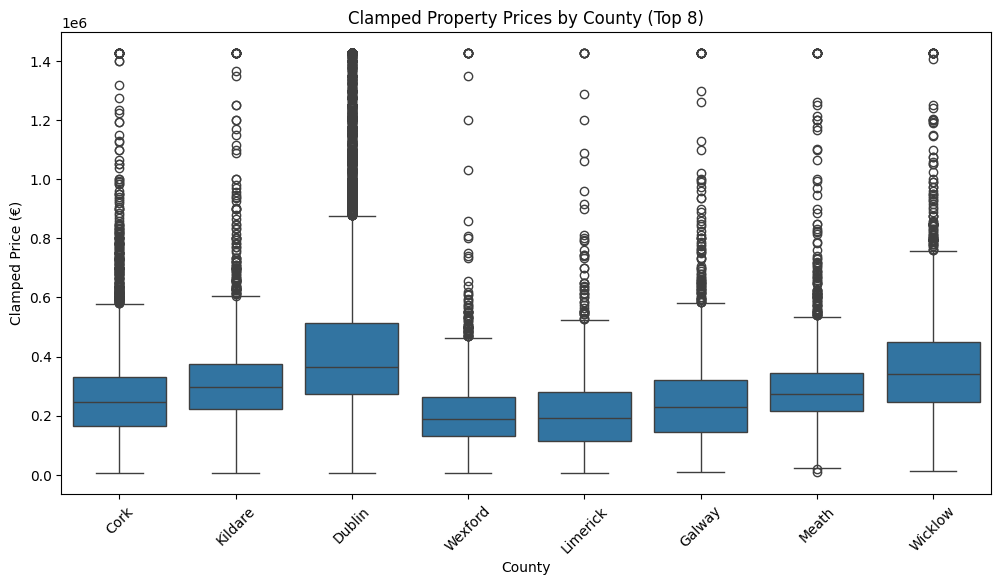

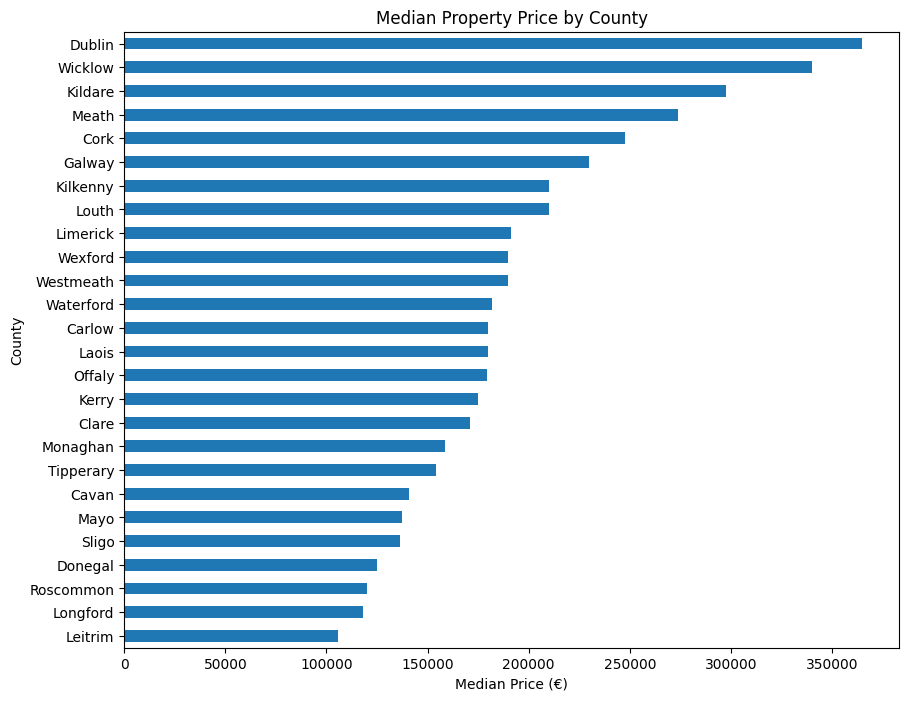

In [22]:
# Select top 8 counties by frequency
top_counties = train_clean_final['county'].value_counts().nlargest(8).index

df_top = train_clean_final[train_clean_final['county'].isin(top_counties)]

# boxplot
plt.figure(figsize=(12,6))

sns.boxplot(
    x='county',
    y='clamped_price',
    data=df_top
)

plt.title('Clamped Property Prices by County (Top 8)')
plt.xlabel('County')
plt.ylabel('Clamped Price (€)')
plt.xticks(rotation=45)

plt.show()

median_prices = train_clean_final.groupby('county', observed=True)['price'].median().sort_values()

plt.figure(figsize=(10,8))
median_prices.plot(kind='barh')

plt.title('Median Property Price by County')
plt.xlabel('Median Price (€)')
plt.ylabel('County')

plt.show()

## 3.3 Price vs Description of Property

The boxplot shows that the median price of new dwellings is higher than that of second-hand properties, indicating that new properties tend to be more expensive. The interquartile range for both categories suggests a substantial spread in prices, although there is considerable overlap between the two distributions. This indicates that while property type influences price, it is not the sole determining factor.


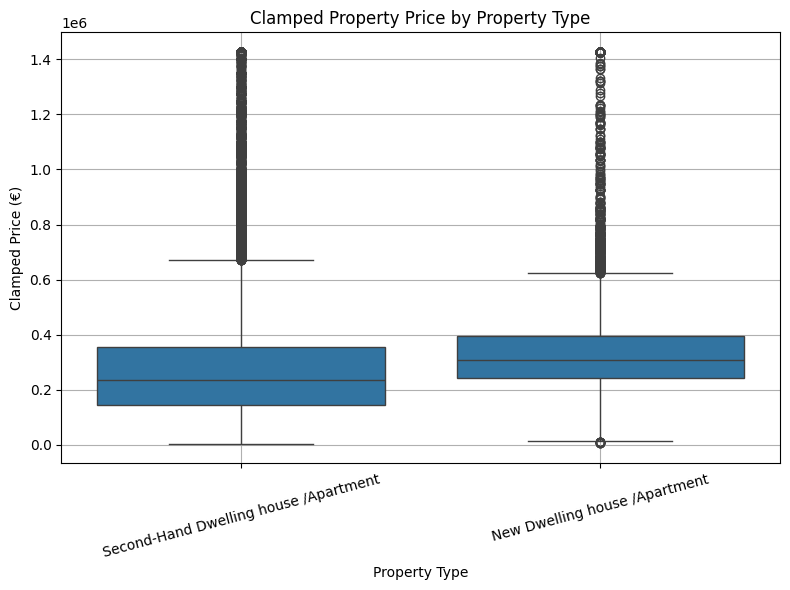

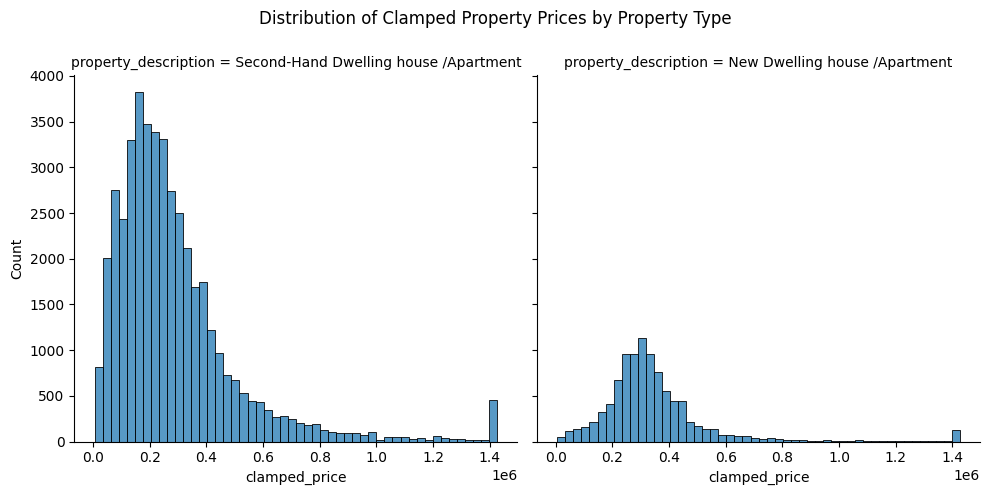

In [23]:
plt.figure(figsize=(8,6))

sns.boxplot(
    x='property_description',
    y='clamped_price',
    data=train_clean_final
)

plt.title('Clamped Property Price by Property Type')
plt.xlabel('Property Type')
plt.ylabel('Clamped Price (€)')
plt.xticks(rotation=15)

plt.grid(True)
plt.tight_layout()
plt.show()

sns.displot(
    data=train_clean_final,
    x='clamped_price',
    col='property_description',
    kind='hist',
    bins=50,
    height=5,
    aspect=1
)

plt.subplots_adjust(top=0.85)
plt.suptitle('Distribution of Clamped Property Prices by Property Type')

plt.show()

## 3.4 Price vs VAT Exclusive

The relationship between property price and VAT status was examined using a boxplot. The results show that properties recorded as VAT exclusive have a higher median price than those that are not VAT exclusive. This suggests that VAT-exclusive transactions are generally associated with more expensive properties. However, there is considerable overlap between the distributions, indicating that VAT status alone does not fully explain price variation. This relationship is likely influenced by the fact that VAT-exclusive properties are more commonly associated with new residences, which tend to have higher prices.


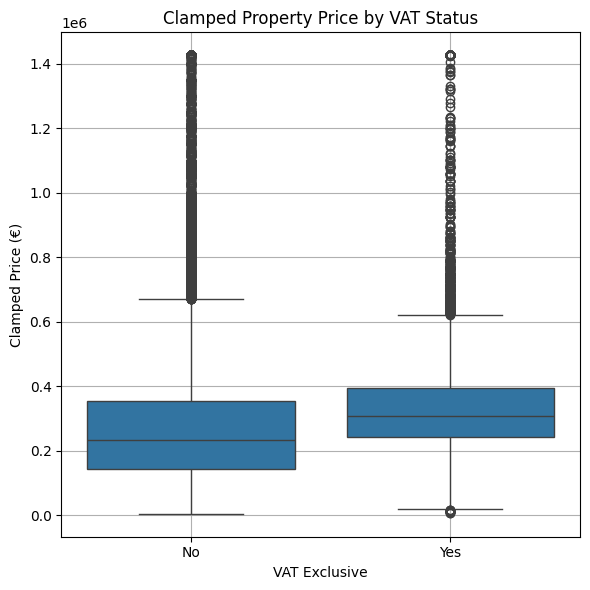

In [24]:
plt.figure(figsize=(6,6))

sns.boxplot(
    x='vat_exclusive',
    y='clamped_price',
    data=train_clean_final
)

plt.title('Clamped Property Price by VAT Status')
plt.xlabel('VAT Exclusive')
plt.ylabel('Clamped Price (€)')

plt.grid(True)
plt.tight_layout()
plt.show()

## 3.5 Price vs Not Full Market Price

The relationship between property price and market type was examined using a boxplot. The results show that properties classified as not full market price have a noticeably lower median price compared to full market transactions. The distribution of full market prices exhibits a wider spread and a greater number of high-value transactions, suggesting that higher-priced properties are more commonly sold under standard market conditions. While this feature is associated with price differences, it reflects transaction characteristics rather than intrinsic property value.


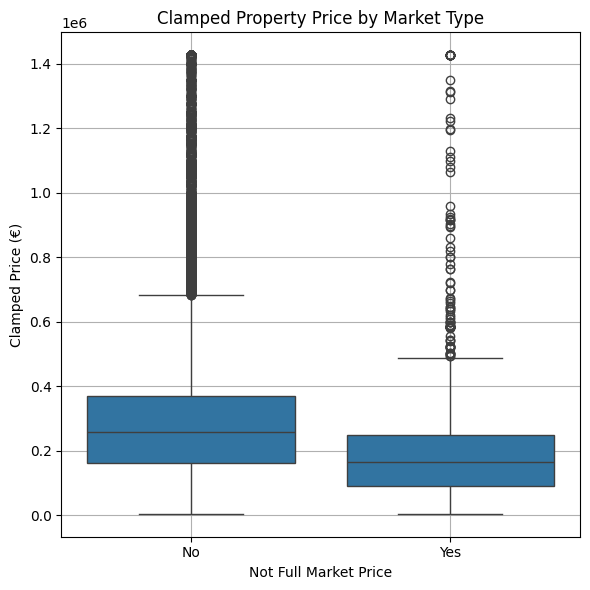

In [25]:
plt.figure(figsize=(6,6))

sns.boxplot(
    x='not_full_market_price',
    y='clamped_price',
    data=train_clean_final
)

plt.title('Clamped Property Price by Market Type')
plt.xlabel('Not Full Market Price')
plt.ylabel('Clamped Price (€)')

plt.grid(True)
plt.tight_layout()
plt.show()

## 3.6 Price vs County and Property Type

To examine interactions between multiple features, the relationship between property price, county, and property type was analysed. The results show that new dwellings generally achieve higher prices than second-hand properties across most counties. However, the magnitude of this difference varies by location, with some counties exhibiting a larger gap between property types than others. Additionally, the overall price levels remain strongly influenced by county, with properties in Dublin and surrounding regions consistently achieving higher values regardless of type. This indicates that while property type affects price, its impact is moderated by geographic location, highlighting the importance of considering feature interactions when modelling property prices.



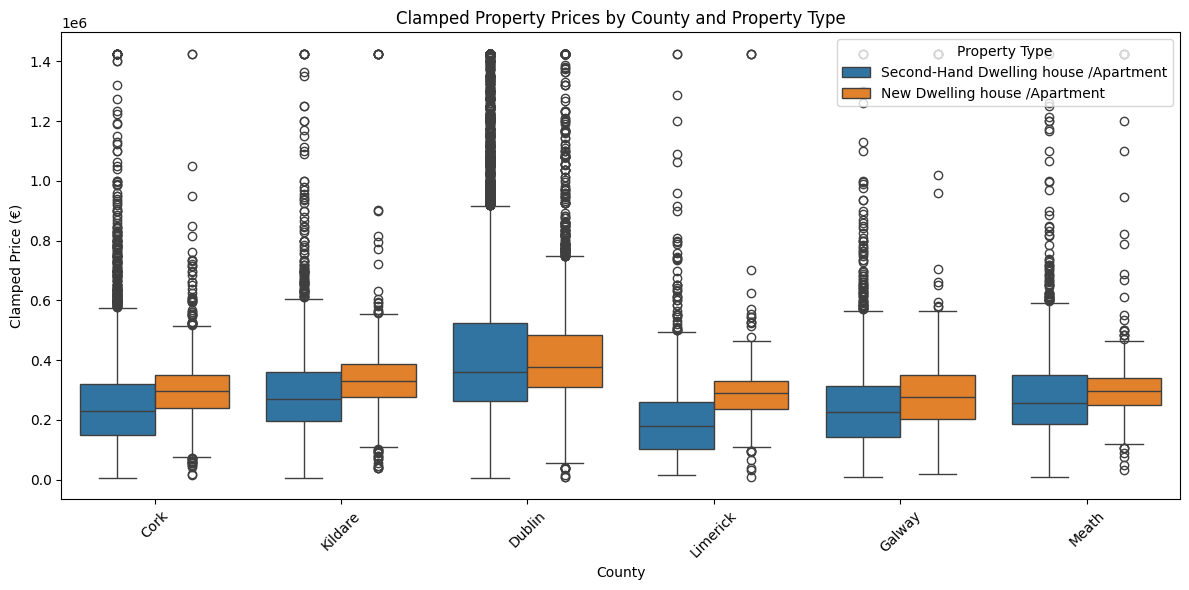

In [26]:
plt.figure(figsize=(12,6))

sns.boxplot(
    x='county',
    y='clamped_price',
    hue='property_description',
    data=train_clean_final[train_clean_final['county'].isin(train_clean_final['county'].value_counts().nlargest(6).index)]
)

plt.title('Clamped Property Prices by County and Property Type')
plt.xlabel('County')
plt.ylabel('Clamped Price (€)')
plt.xticks(rotation=45)

plt.legend(title='Property Type')
plt.tight_layout()
plt.show()

In [27]:
duplicate_columns = train_dqr.columns[train_dqr.columns.duplicated()].tolist()
constant_columns = [
    col for col in train_dqr.columns
    if train_dqr[col].nunique(dropna=False) <= 1
]

print("Duplicate columns:", duplicate_columns if duplicate_columns else "None")
print("Constant columns:", constant_columns if constant_columns else "None")

Duplicate columns: None
Constant columns: None


## Overall Findings

The analysis of relationships between features and property price highlights several key drivers of housing prices within the dataset. A clear upward trend over time indicates sustained growth in property values between 2016 and 2024. Geographic location emerges as one of the most influential factors, with properties in Dublin and surrounding counties consistently achieving higher prices than those in more rural regions. Property type also plays a role, with new dwellings generally commanding higher prices than second-hand properties; however, this effect varies across counties, suggesting an interaction between location and property characteristics. Additional features such as VAT status and market type show observable relationships with price, although these appear to reflect underlying transaction conditions rather than intrinsic property value.

These findings directly inform the feature engineering process. In particular, the strong temporal trend motivates the creation of continuous and seasonal time-based features (Sale_YearMonth and Sale_Month) to capture both long-term growth and intra-year variation. The dominant influence of geographic location supports the use of geocoding to derive latitude and longitude for each property, enabling a more granular representation of location than county alone. These coordinates will subsequently be used to link properties to external CSO data, allowing the incorporation of area-level socio-economic indicators such as population density. Overall, this approach aims to capture the key temporal and spatial drivers of property price identified in the analysis.

----------------------------------------------------------------------------------------

## 4. Feature Engineering

The final model used both temporal features and external CSO small-area features. This gives the model more local socioeconomic context than county alone.

Engineered features used here:

- `Sale_MonthYear`
- weekday and month one-hot encodings
- latitude and longitude from geocoding
- a binary `is_new` feature
- multiple CSO small-area ratio features

## Latitude and Longitude

To improve the geographic representation of each transaction, latitude and longitude were derived from the cleaned address using geocoding (found in notebooks/geocoding.ipynb). County alone captures broad regional variation, but it does not reflect within-county differences in location. Latitude and longitude provide a continuous spatial representation and allow the model to capture local price patterns more precisely. The spatial plot shows clear geographic clustering and visible variation in price across locations, supporting the inclusion of these features in the predictive model.

In [28]:
# Load in geocoded train and test
train_geo = pd.read_csv("../data/ppr-group-25200353-train-geocoded.csv", parse_dates=["date_of_sale"])
test_geo = pd.read_csv("../data/ppr-group-25200353-test-geocoded.csv", parse_dates=["date_of_sale"])

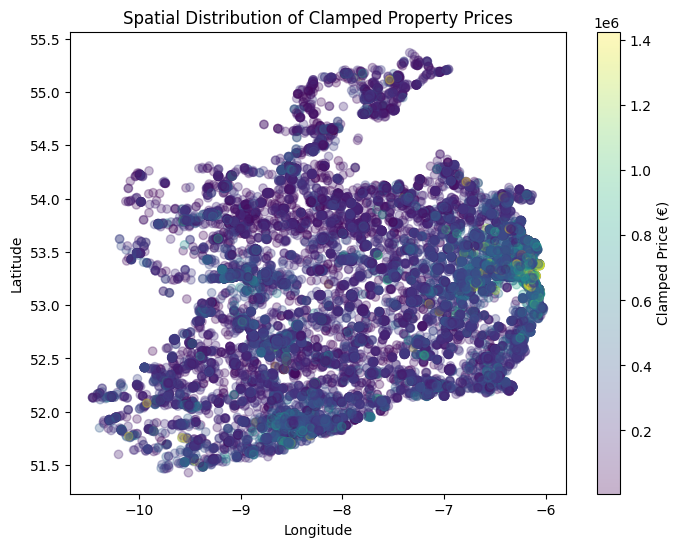

In [29]:
plt.figure(figsize=(8, 6))
plt.scatter(
    train_geo["longitude"],
    train_geo["latitude"],
    c=train_geo["clamped_price"],
    cmap="viridis",
    alpha=0.3
)
plt.colorbar(label="Clamped Price (€)")
plt.title("Spatial Distribution of Clamped Property Prices")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

## Sale_YearMonth

To capture the temporal trend in property prices, a new continuous feature, Sale_YearMonth, was created by converting the sale date into a numeric representation of months since the start of the dataset. This allows time to be treated as a continuous variable suitable for modelling.

The relationship between this feature and property price was examined using both a scatter plot with a fitted regression line and a plot of median prices over time. The scatter plot shows a general upward trend, although with substantial variability due to differences in property characteristics and location. This is reflected in a relatively modest correlation coefficient (approximately 0.20), indicating that time alone does not fully explain variation in prices.

However, the median price plot reveals a clear and consistent increase in property values over time, rising from approximately €170,000 at the beginning of the dataset to over €330,000 in later years. This demonstrates a strong underlying temporal trend that is not fully captured by simple correlation due to the high variability in individual transactions.

Based on these findings, the Sale_YearMonth feature was retained as it effectively captures the long-term upward trend in property prices and is expected to contribute meaningful predictive information when combined with other features.

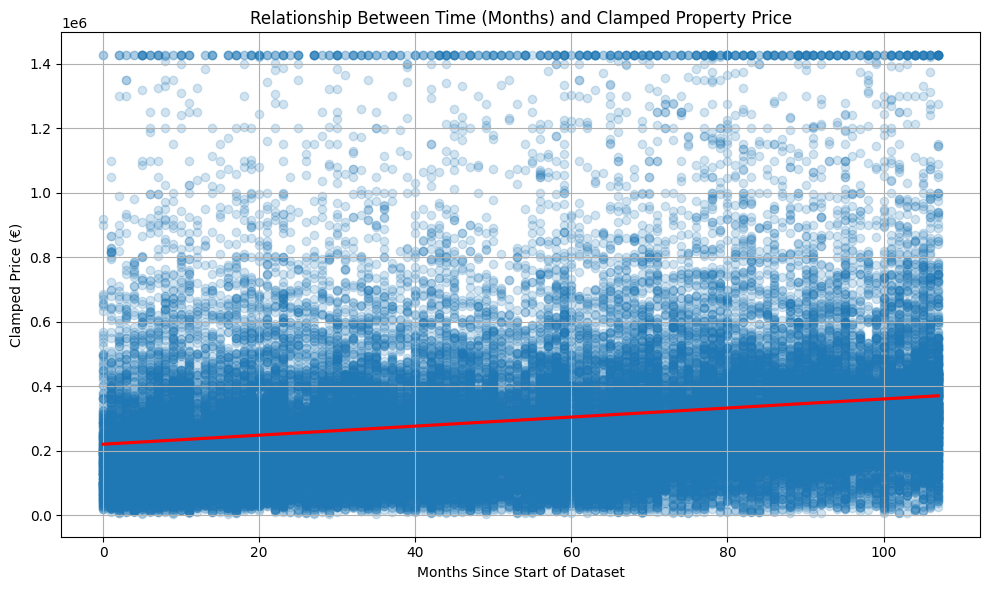

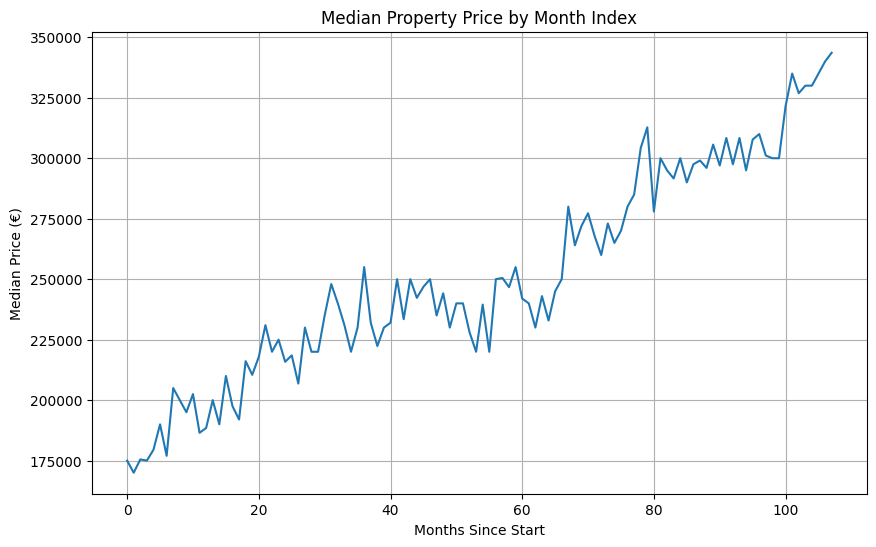

,Sale_YearMonth,price
Sale_YearMonth,1.000000,0.052818
price,0.052818,1.000000


In [30]:
# Create new continuous temporal feature: Sale_YearMonth
train_geo['Sale_YearMonth'] = (
    train_geo['date_of_sale'].dt.year * 12
    + train_geo['date_of_sale'].dt.month
)

train_geo['Sale_YearMonth'] = train_geo['Sale_YearMonth'] - train_geo['Sale_YearMonth'].min()

plt.figure(figsize=(10,6))

sns.regplot(
    x='Sale_YearMonth',
    y='clamped_price',
    data=train_geo,
    scatter_kws={'alpha':0.2},
    line_kws={'color':'red'}
)

plt.title('Relationship Between Time (Months) and Clamped Property Price')
plt.xlabel('Months Since Start of Dataset')
plt.ylabel('Clamped Price (€)')

plt.grid(True)
plt.tight_layout()
plt.show()

# Median Price by month
train_geo.groupby('Sale_YearMonth')['price'].median().plot(figsize=(10,6))

plt.title('Median Property Price by Month Index')
plt.xlabel('Months Since Start')
plt.ylabel('Median Price (€)')
plt.grid(True)
plt.show()

train_geo[['Sale_YearMonth', 'price']].corr()

## Sale_Month

A seasonal feature, Sale_Month, was created to investigate whether property prices vary systematically within a calendar year. The monthly median plot shows moderate variation in prices across months, with lower values earlier in the year and higher values towards the later months, peaking around October in the aggregated data. When examined separately by year, the same pattern is not identical in every year, but later months are often associated with relatively higher median prices. This suggests that Sale_Month may capture some seasonal variation in the housing market, although the effect appears weaker and less consistent than the long-term temporal trend captured by Sale_YearMonth.

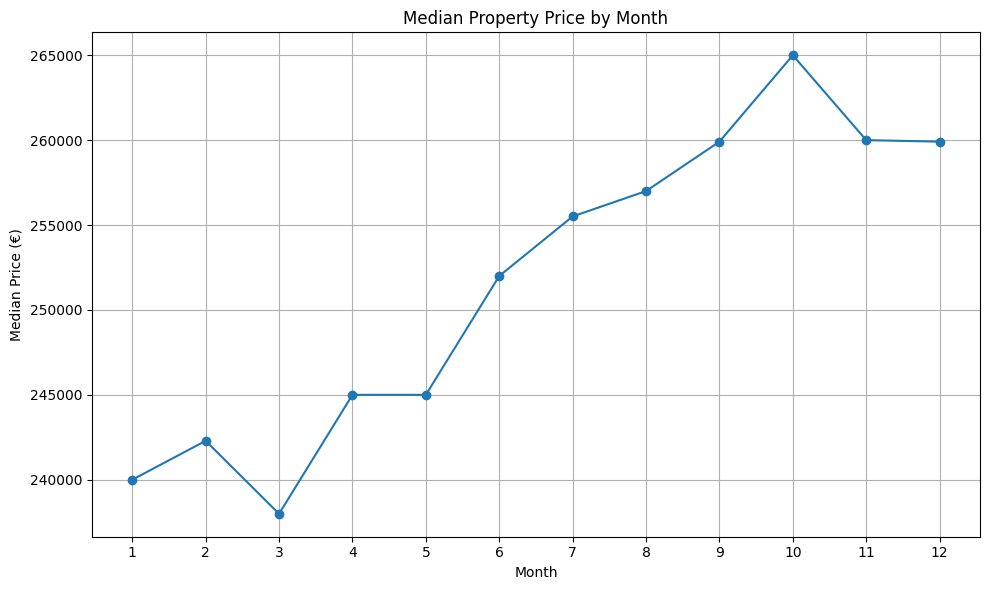

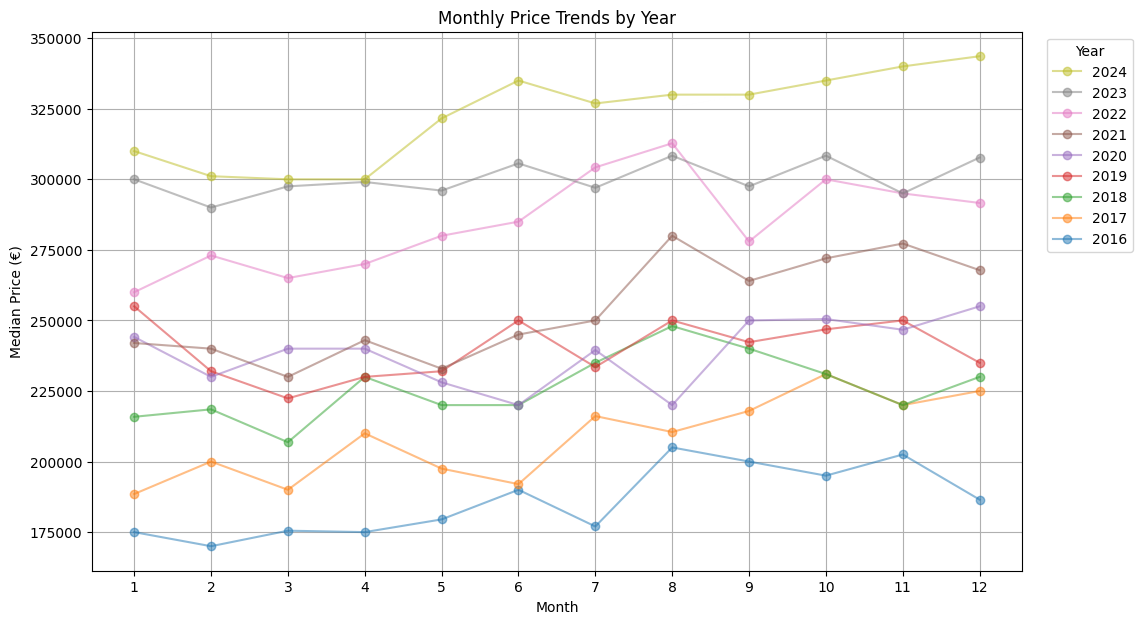

In [31]:
train_geo['Sale_Month'] = train_geo['date_of_sale'].dt.month
train_geo['Sale_Year'] = train_geo['date_of_sale'].dt.year

# Overall monthly pattern
monthly_median = (
    train_geo.groupby('Sale_Month')['price']
    .median()
    .sort_index()
    )

plt.figure(figsize=(10,6))
monthly_median.plot(marker='o')
plt.title('Median Property Price by Month')
plt.xlabel('Month')
plt.ylabel('Median Price (€)')
plt.xticks(range(1,13))
plt.grid(True)
plt.tight_layout()
plt.show()

# Monthly trend by year
monthly_trends = (
    train_geo.groupby(['Sale_Year', 'Sale_Month'])['price']
    .median()
    .unstack()
)

plt.figure(figsize=(12,7))
for year in monthly_trends.index:
    plt.plot(monthly_trends.columns, 
             monthly_trends.loc[year], 
             alpha=0.5,
             marker='o',
             label=str(year)
        )

plt.title('Monthly Price Trends by Year')
plt.xlabel('Month')
plt.ylabel('Median Price (€)')
plt.xticks(range(1,13))
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(
    handles[::-1],
    labels[::-1],
    title='Year', 
    bbox_to_anchor=(1.02, 1), 
    loc='upper left'
)
plt.grid(True)
plt.show()

## is_new

The Description of Property feature was transformed into a binary indicator variable (is_new) to simplify the representation of property type. This transformation reduces categorical complexity and allows the model to capture the difference between new and second-hand properties more directly. Analysis of median prices shows that new properties tend to have higher prices than second-hand properties, indicating that this feature contains predictive information.

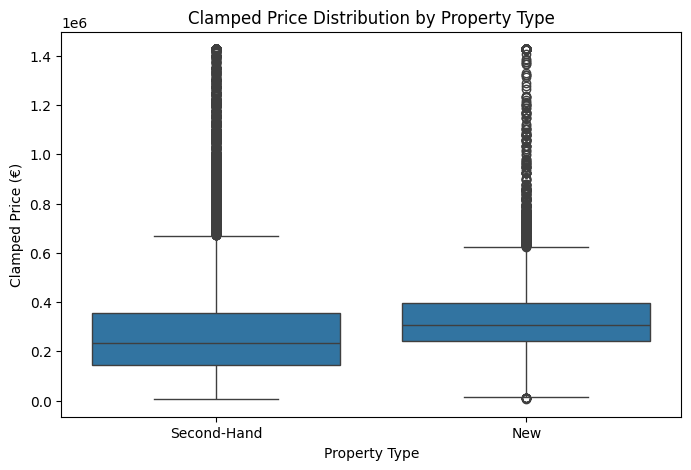

is_new
0    235000.00
1    308370.05
Name: clamped_price, dtype: float64

In [32]:
train_geo["is_new"] = train_geo["property_description"].map({
        "Second-Hand Dwelling house /Apartment": 0,
        "New Dwelling house /Apartment": 1,
    })
train_geo["is_new_label"] = train_geo["is_new"].map({
    0: "Second-Hand",
    1: "New"
})

plt.figure(figsize=(8, 5))
sns.boxplot(data=train_geo, x="is_new_label", y="clamped_price")
plt.title("Clamped Price Distribution by Property Type")
plt.xlabel("Property Type")
plt.ylabel("Clamped Price (€)")
plt.show()
train_geo.groupby('is_new')['clamped_price'].median()

The engineered features used for modelling are intended to capture temporal trend, seasonality, location, and small area socioeconomic context. This addresses the requirement to create at least three domain-informed features and to show how external CSO data can improve the representation of a property sale beyond the raw RPPR fields alone.

----------------------------------------------------------------------------------------

## 5. Training and Evaluating Models

We use the geocoded training set as the modelling base because the location features are central to the final solution. The evaluation is time-aware:

- cross-validation uses `TimeSeriesSplit`;
- the separate geocoded test set is used as the final hold-out evaluation;
- three metrics are reported: MAE, RMSE and R².

To make the target-transformation choice explicit, we compare four targets:

- `price`
- `clamped_price`
- `log_price`
- `clamped_log_price`

Each target is trained with both a linear model and a nonlinear random forest. For transformed targets, we also convert predictions back to euro so they can be compared on a common price scale.

## 5.1 Applying same preprocessing to the test set

The same cleaning steps developed on the training set were applied to the raw test set using the reusable clean_dataframe() function. Crucially, the upper price cap learned from the training data was reused rather than recalculated on the test set, preventing data leakage and ensuring consistent preprocessing.

In [33]:
# Reuse clean_dataframe function to clean test data, then geocode using geocoding.ipynb
test_raw = pd.read_csv("../data/ppr-group-25200353-test.csv")
test_clean_final, _ = clean_dataframe(test_raw, upper_price_cap=upper_price_cap)

print(f"Test shape: {test_clean_final.shape}")

test_clean_final.to_csv("../data/ppr-group-25200353-test-clean-final.csv", index=False)

Test shape: (9998, 8)


## 5.2 Base dataframe for modelling

A base dataframe was created using the common features shared by all models evaluated

In [34]:
def base_model_frame(df):
    frame = df.copy()
    frame["date_of_sale"] = pd.to_datetime(frame["date_of_sale"])

    frame["Sale_YearMonth"] = (
        frame["date_of_sale"].dt.year * 12 + frame["date_of_sale"].dt.month
    )
    frame["Sale_YearMonth"] = frame["Sale_YearMonth"] - frame["Sale_YearMonth"].min()

    frame["Sale_Month"] = frame["date_of_sale"].dt.month

    frame["is_new"] = frame["property_description"].map({
        "Second-Hand Dwelling house /Apartment": 0,
        "New Dwelling house /Apartment": 1,
    })

    baseline_features = [
        "Sale_YearMonth",
        "Sale_Month",
        "is_new",
        "latitude",
        "longitude",
    ]

    return frame, baseline_features

In [35]:
train_common_df, baseline_features = base_model_frame(train_geo)
test_common_df, _ = base_model_frame(test_geo)

X_train = train_common_df[baseline_features].copy()
X_test = test_common_df[baseline_features].copy()

train_price = train_common_df["price"].copy()
test_price = test_common_df["price"].copy()

## 5.3 Targets

Because the target variable is strongly right-skewed, four target definitions were evaluated: raw price, clamped price, log-transformed price, and clamped log-transformed price. This allowed us to test whether reducing skewness and limiting extreme upper-tail values improved predictive performance.

In [36]:
price_cap = train_price.quantile(0.99) # original price

target_definitions = {
    "price": {
        "y_train": train_price,
        "y_test": test_price,
        "inverse": lambda x: x,
    },
    "clamped_price": {
        "y_train": train_price.clip(upper=price_cap),
        "y_test": test_price.clip(upper=price_cap),
        "inverse": lambda x: x,
    },
    "log_price": {
        "y_train": np.log1p(train_price),
        "y_test": np.log1p(test_price),
        "inverse": np.expm1,
    },
    "clamped_log_price": {
        "y_train": np.log1p(train_price.clip(upper=price_cap)),
        "y_test": np.log1p(test_price.clip(upper=price_cap)),
        "inverse": np.expm1,
    },
}

In [37]:
numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

tree_numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
])

linear_model = Pipeline([
    ("preprocess", ColumnTransformer(
        transformers=[("num", numeric_preprocessor, baseline_features)],
        remainder="drop",
    )),
    ("regressor", LinearRegression()),
])

random_forest_model = Pipeline([
    ("preprocess", ColumnTransformer(
        transformers=[("num", tree_numeric_preprocessor, baseline_features)],
        remainder="drop",
    )),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        max_depth=20,
        min_samples_split=5,
        min_samples_leaf=3,
        max_features="sqrt",
        n_jobs=-1,
        random_state=42,
    )),
])

model_makers = {
    "Linear Regression": lambda: Pipeline(steps=linear_model.steps),
    "Random Forest": lambda: Pipeline(steps=random_forest_model.steps),
}

In [38]:
def summarise_scores(target_name, model_name, model, X_train, X_test, y_train, y_test, inverse):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    cv = TimeSeriesSplit(n_splits=5)
    cv_scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2",
        },
        n_jobs=-1,
    )

    train_metrics_target = {
        "target": target_name,
        "metric_scale": "target_scale",
        "split": "train",
        "model": model_name,
        "mae": mean_absolute_error(y_train, train_pred),
        "rmse": mean_squared_error(y_train, train_pred) ** 0.5,
        "r2": r2_score(y_train, train_pred),
    }

    cv_metrics_target = {
        "target": target_name,
        "metric_scale": "target_scale",
        "split": "time_series_cv_mean",
        "model": model_name,
        "mae": -cv_scores["test_mae"].mean(),
        "rmse": -cv_scores["test_rmse"].mean(),
        "r2": cv_scores["test_r2"].mean(),
    }

    test_metrics_target = {
        "target": target_name,
        "metric_scale": "target_scale",
        "split": "test",
        "model": model_name,
        "mae": mean_absolute_error(y_test, test_pred),
        "rmse": mean_squared_error(y_test, test_pred) ** 0.5,
        "r2": r2_score(y_test, test_pred),
    }

    train_pred_price = inverse(train_pred)
    test_pred_price = inverse(test_pred)
    y_train_price = inverse(y_train)
    y_test_price = inverse(y_test)

    train_metrics_price = {
        "target": target_name,
        "metric_scale": "price_scale",
        "split": "train",
        "model": model_name,
        "mae": mean_absolute_error(y_train_price, train_pred_price),
        "rmse": mean_squared_error(y_train_price, train_pred_price) ** 0.5,
        "r2": r2_score(y_train_price, train_pred_price),
    }

    test_metrics_price = {
        "target": target_name,
        "metric_scale": "price_scale",
        "split": "test",
        "model": model_name,
        "mae": mean_absolute_error(y_test_price, test_pred_price),
        "rmse": mean_squared_error(y_test_price, test_pred_price) ** 0.5,
        "r2": r2_score(y_test_price, test_pred_price),
    }

    return [
        train_metrics_target,
        cv_metrics_target,
        test_metrics_target,
        train_metrics_price,
        test_metrics_price,
    ]

## 5.4 Evaluation approach

Three evaluation settings were used:

- Training performance: fit and evaluate on the training set. This provides an optimistic upper bound.
- Time-series cross-validation: TimeSeriesSplit was used to preserve temporal ordering, training on earlier periods and validating on later periods.
- Hold-out test evaluation: the final model was fitted on the training data and evaluated on the separate cleaned test set.

Three metrics were reported throughout: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and *R^2*.

In [39]:
results = []
fitted_models = {}

for target_name, definition in target_definitions.items():
    for model_name, model_maker in model_makers.items():
        model = model_maker()

        results.extend(
            summarise_scores(
                target_name=target_name,
                model_name=model_name,
                model=model,
                X_train=X_train,
                X_test=X_test,
                y_train=definition["y_train"],
                y_test=definition["y_test"],
                inverse=definition["inverse"],
            )
        )

        if target_name == "clamped_log_price":
            fitted_models[model_name] = model

results_df = pd.DataFrame(results)
results_df[["mae", "rmse"]] = results_df[["mae", "rmse"]].round(2)
results_df["r2"] = results_df["r2"].round(4)

display(results_df.sort_values(["metric_scale", "split", "target", "model"]).reset_index(drop=True))

,target,metric_scale,split,model,mae,rmse,r2
0,clamped_log_price,price_scale,test,Linear Regression,196838.79,291344.02,-0.4165
1,clamped_log_price,price_scale,test,Random Forest,183733.95,259414.77,-0.1230
2,clamped_price,price_scale,test,Linear Regression,170480.35,263146.27,-0.1556
3,clamped_price,price_scale,test,Random Forest,162940.55,236478.73,0.0668
4,log_price,price_scale,test,Linear Regression,230917.54,880267.02,-0.0486
5,log_price,price_scale,test,Random Forest,217770.39,866588.11,-0.0162
6,price,price_scale,test,Linear Regression,201464.88,865317.91,-0.0133
7,price,price_scale,test,Random Forest,201402.24,859122.43,0.0012
8,clamped_log_price,price_scale,train,Linear Regression,127211.50,210176.70,0.1128
9,clamped_log_price,price_scale,train,Random Forest,74447.84,137391.95,0.6209


In [40]:
price_scale_test = (
    results_df[
        (results_df["metric_scale"] == "price_scale")
        & (results_df["split"] == "test")
    ]
    .sort_values(["rmse", "mae"])
    .reset_index(drop=True)
)

display(price_scale_test)

,target,metric_scale,split,model,mae,rmse,r2
0,clamped_price,price_scale,test,Random Forest,162940.55,236478.73,0.0668
1,clamped_log_price,price_scale,test,Random Forest,183733.95,259414.77,-0.1230
2,clamped_price,price_scale,test,Linear Regression,170480.35,263146.27,-0.1556
3,clamped_log_price,price_scale,test,Linear Regression,196838.79,291344.02,-0.4165
4,price,price_scale,test,Random Forest,201402.24,859122.43,0.0012
5,price,price_scale,test,Linear Regression,201464.88,865317.91,-0.0133
6,log_price,price_scale,test,Random Forest,217770.39,866588.11,-0.0162
7,log_price,price_scale,test,Linear Regression,230917.54,880267.02,-0.0486


### Baseline Model Performance

The baseline models show limited predictive performance on the hold-out test set. Linear Regression performs poorly, and even the better Random Forest variants achieve only modest test *R^2* values.

This indicates that the baseline feature set captures only a small share of the variation in sale price. At this stage, the models appear to learn some broad temporal and spatial signal, but they do not explain raw property prices well enough for strong predictive accuracy.


Effect of Target Transformations - Several target transformations were evaluated, including clamped and log-transformed price variants. However, these transformations did not lead to meaningful improvements in predictive performance. In particular, models trained on log-transformed targets often resulted in negative *R^2* scores when evaluated on the original price scale.

Overfitting Analysis - A clear indication of overfitting is observed in the Random Forest models. While training performance is strong (e.g., *R^2* ≈ 0.70), test performance is substantially lower (e.g., *R^2* ≈ 0.07). This large gap indicates that the model is learning patterns specific to the training data that do not generalise well to unseen observations. Time-series cross-validation results fall between training and test performance, further confirming that the model has limited generalisation ability.


The primary limitation of the baseline model is the lack of sufficiently informative features. While temporal and basic spatial features are included, the model lacks detailed information about property characteristics and local neighbourhood context, which are known to be critical drivers of property prices.

## 5.5 Improved Model: Adding Small-Area and Calendar Features

In [41]:
def build_small_area_features():
    saps = pd.read_csv('../data/saps_small_areas.csv', dtype={"GEOGID": str})
    used_small_areas = (
        set(train_geo["cso_small_area"].dropna().astype(str))
        | set(test_geo["cso_small_area"].dropna().astype(str))
    )
    saps = saps[saps["GEOGID"].isin(used_small_areas)].copy()

    small_area = pd.DataFrame({"cso_small_area": saps["GEOGID"]})

    young_cols = [f"T1_1AGE{i}T" for i in range(20)] + ["T1_1AGE20_24T"]
    old_cols = [
        "T1_1AGE65_69T",
        "T1_1AGE70_74T",
        "T1_1AGE75_79T",
        "T1_1AGE80_84T",
        "T1_1AGEGE_85T",
    ]

    small_area["sa_pct_young"]                   = saps[young_cols].sum(axis=1) / saps["T1_1AGETT"]
    small_area["sa_pct_old"]                     = saps[old_cols].sum(axis=1) / saps["T1_1AGETT"]
    
    small_area["sa_share_at_work"]               = saps["T8_1_WT"] / saps["T8_1_TT"]
    small_area["sa_share_long_term_unemployed"]  = saps["T8_1_LTUT"] / saps["T8_1_TT"]
    small_area["sa_share_student"]               = saps["T8_1_STUT"] / saps["T8_1_TT"]
    
    small_area["sa_share_higher_degree_plus"]    = saps["T10_4_HDPQT"] / saps["T10_4_TT"]
    small_area["sa_share_lower_education"]       = saps["T10_4_ODNDT"] / saps["T10_4_TT"]
    
    small_area["sa_share_owned_mortgage"]        = saps["T6_3_OMLP"] / saps["T6_3_TP"]
    small_area["sa_share_private_rent"]          = saps["T6_3_RPLP"] / saps["T6_3_TP"]
    small_area["sa_share_social_housing"]        = saps["T6_3_RLAP"] / saps["T6_3_TP"]
    
    small_area["sa_share_one_person_households"] = saps["T5_1OP_H"] / saps["T5_1T_H"]
    small_area["sa_share_couples_with_children"] = saps["T5_1MCC_H"] / saps["T5_1T_H"]
    
    small_area["sa_share_car_driver"]            = saps["T11_1_CDT"] / saps["T11_1_TT"]
    small_area["sa_share_work_from_home"]        = saps["T11_4_WFH"] / saps["T11_4_T"]

    return small_area


WEEKDAY_ORDER = [
    "monday",
    "tuesday",
    "wednesday",
    "thursday",
    "friday",
    "saturday",
    "sunday",
]
MONTH_ORDER = [
    "january",
    "february",
    "march",
    "april",
    "may",
    "june",
    "july",
    "august",
    "september",
    "october",
    "november",
    "december",
]


def build_model_frame(df, base_yearmonth, small_area_features):
    frame = df.copy()
    frame["date_of_sale"] = pd.to_datetime(frame["date_of_sale"])

    # Part 4 engineered features
    yearmonth = (
        frame["date_of_sale"].dt.year * 12
        + frame["date_of_sale"].dt.month
    )
    frame["Sale_YearMonth"] = yearmonth - base_yearmonth
    frame["Sale_Month"] = frame["date_of_sale"].dt.month

    frame["is_not_full_market_price"] = frame["not_full_market_price"].map({"No": 0, "Yes": 1})
    frame["is_new"] = frame["property_description"].map({
        "Second-Hand Dwelling house /Apartment": 0,
        "New Dwelling house /Apartment": 1,
    })

    # Extra calendar encoding for improved model
    weekday = pd.Categorical(
        frame["date_of_sale"].dt.day_name().str.lower(),
        categories=WEEKDAY_ORDER,
        ordered=True,
    )
    month = pd.Categorical(
        frame["date_of_sale"].dt.month_name().str.lower(),
        categories=MONTH_ORDER,
        ordered=True,
    )

    weekday_dummies = pd.get_dummies(weekday, prefix="weekday", drop_first=True, dtype=int)
    month_dummies = pd.get_dummies(month, prefix="month", drop_first=True, dtype=int)

    # Merge CSO small-area features
    frame["cso_small_area"] = frame["cso_small_area"].astype(str)
    frame = frame.merge(small_area_features, on="cso_small_area", how="left")

    frame = pd.concat([frame, weekday_dummies, month_dummies], axis=1)

    continuous_features = [
        "Sale_YearMonth",
        "Sale_Month",
        "latitude",
        "longitude",
    ] + [col for col in small_area_features.columns if col != "cso_small_area"]

    dummy_features = (
        ["is_not_full_market_price", "is_new"]
        + weekday_dummies.columns.tolist()
        + month_dummies.columns.tolist()
    )

    return frame, continuous_features, dummy_features

train_geo["date_of_sale"] = pd.to_datetime(train_geo["date_of_sale"])
test_geo["date_of_sale"] = pd.to_datetime(test_geo["date_of_sale"])

base_yearmonth = (
    train_geo["date_of_sale"].dt.year * 12
    + train_geo["date_of_sale"].dt.month
).min()

small_area_features = build_small_area_features()

train_model_df, continuous_features, dummy_features = build_model_frame(
    train_geo, base_yearmonth, small_area_features
)
test_model_df, _, _ = build_model_frame(
    test_geo, base_yearmonth, small_area_features
)

In [42]:
X_train = train_model_df[continuous_features + dummy_features].copy()
X_test = test_model_df[continuous_features + dummy_features].copy()

train_price = train_model_df["price"].copy()
test_price = test_model_df["price"].copy()

price_cap = train_price.quantile(0.99)
clamped_train_price = train_price.clip(upper=price_cap)
clamped_test_price = test_price.clip(upper=price_cap)

target_definitions = {
    "price": {
        "y_train": train_price,
        "y_test": test_price,
        "inverse": lambda x: x,
    },
    "clamped_price": {
        "y_train": clamped_train_price,
        "y_test": clamped_test_price,
        "inverse": lambda x: x,
    },
    "log_price": {
        "y_train": np.log1p(train_price),
        "y_test": np.log1p(test_price),
        "inverse": np.expm1,
    },
    "clamped_log_price": {
        "y_train": np.log1p(clamped_train_price),
        "y_test": np.log1p(clamped_test_price),
        "inverse": np.expm1,
    },
}

pd.DataFrame({
    "target": list(target_definitions.keys()),
    "train_mean": [definition["y_train"].mean() for definition in target_definitions.values()],
    "train_std": [definition["y_train"].std() for definition in target_definitions.values()],
}).round(4)

numeric_preprocessor = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

tree_numeric_preprocessor = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median"))]
)

linear_model = Pipeline(
    steps=[
        (
            "preprocess",
            ColumnTransformer(
                transformers=[("num", numeric_preprocessor, continuous_features)],
                remainder="passthrough",
            ),
        ),
        ("regressor", LinearRegression()),
    ]
)

random_forest_model = Pipeline(
    steps=[
        (
            "preprocess",
            ColumnTransformer(
                transformers=[("num", tree_numeric_preprocessor, continuous_features)],
                remainder="passthrough",
            ),
        ),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=200,
                max_depth=20,
                min_samples_split=5,
                min_samples_leaf=3,
                max_features="sqrt",
                n_jobs=-1,
                random_state=42,
            ),
        ),
    ]
)

model_makers = {
    "Linear Regression": lambda: Pipeline(steps=linear_model.steps),
    "Random Forest": lambda: Pipeline(steps=random_forest_model.steps),
}

In [43]:
results = []
fitted_models = {}
for target_name, definition in target_definitions.items():
    for model_name, model_maker in model_makers.items():
        model = model_maker()
        results.extend(
            summarise_scores(
                target_name=target_name,
                model_name=model_name,
                model=model,
                X_train=X_train,
                X_test=X_test,
                y_train=definition["y_train"],
                y_test=definition["y_test"],
                inverse=definition["inverse"],
            )
        )

        if target_name == "clamped_log_price":
            fitted_models[model_name] = model

results_df = pd.DataFrame(results)
results_df[["mae", "rmse"]] = results_df[["mae", "rmse"]].round(2)
results_df["r2"] = results_df["r2"].round(4)
results_df.sort_values(["metric_scale", "split", "target", "model"]).reset_index(drop=True)

,target,metric_scale,split,model,mae,rmse,r2
0,clamped_log_price,price_scale,test,Linear Regression,158555.91,235555.61,0.0741
1,clamped_log_price,price_scale,test,Random Forest,150195.48,223272.51,0.1681
2,clamped_price,price_scale,test,Linear Regression,145647.21,219389.78,0.1968
3,clamped_price,price_scale,test,Random Forest,136776.27,206622.44,0.2876
4,log_price,price_scale,test,Linear Regression,193175.69,857400.34,0.0052
5,log_price,price_scale,test,Random Forest,183365.20,853301.12,0.0147
6,price,price_scale,test,Linear Regression,190372.56,849645.73,0.0231
7,price,price_scale,test,Random Forest,185616.00,855008.26,0.0107
8,clamped_log_price,price_scale,train,Linear Regression,110231.21,182763.02,0.3291
9,clamped_log_price,price_scale,train,Random Forest,66417.69,128180.05,0.6700


In [44]:
price_scale_test = (
    results_df[
        (results_df["metric_scale"] == "price_scale")
        & (results_df["split"] == "test")
    ]
    .sort_values(["rmse", "mae"])
    .reset_index(drop=True)
)
price_scale_test

,target,metric_scale,split,model,mae,rmse,r2
0,clamped_price,price_scale,test,Random Forest,136776.27,206622.44,0.2876
1,clamped_price,price_scale,test,Linear Regression,145647.21,219389.78,0.1968
2,clamped_log_price,price_scale,test,Random Forest,150195.48,223272.51,0.1681
3,clamped_log_price,price_scale,test,Linear Regression,158555.91,235555.61,0.0741
4,price,price_scale,test,Linear Regression,190372.56,849645.73,0.0231
5,log_price,price_scale,test,Random Forest,183365.20,853301.12,0.0147
6,price,price_scale,test,Random Forest,185616.00,855008.26,0.0107
7,log_price,price_scale,test,Linear Regression,193175.69,857400.34,0.0052


## 5.6 Improved Model Performance

The introduction of small-area socioeconomic features and additional temporal indicators resulted in a clear improvement in predictive performance compared to the baseline model. The best-performing improved model, a Random Forest trained on the clamped price target, achieved a substantially lower MAE (approximately €136,800) compared to the baseline (approximately €162,900), along with a corresponding reduction in RMSE. This indicates that incorporating richer geographic and neighbourhood-level information provides additional predictive signal beyond basic spatial coordinates and temporal features alone.

While the improved model still exhibits a gap between training and test performance, suggesting some degree of overfitting, the improvement in hold-out test metrics confirms that the additional features contribute meaningfully to generalisation. Overall, these results demonstrate that property price prediction benefits significantly from combining temporal, spatial, and socioeconomic context, rather than relying solely on basic location and time features.

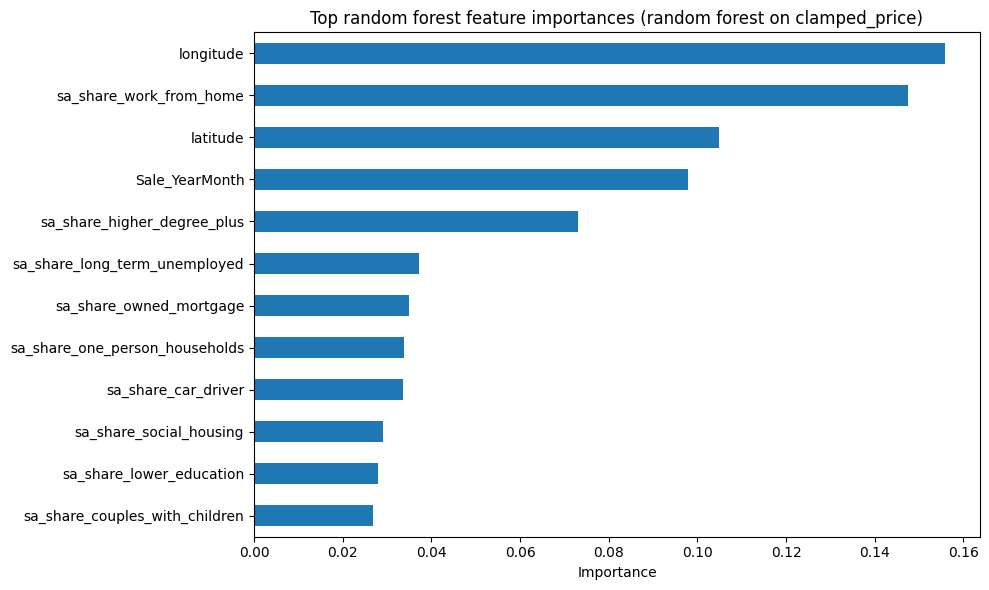

In [45]:
rf_fitted = fitted_models["Random Forest"]

feature_names = continuous_features + dummy_features
importances = rf_fitted.named_steps["regressor"].feature_importances_
importances = pd.Series(importances, index=feature_names).sort_values(ascending=False).head(12)

plt.figure(figsize=(10, 6))
importances.sort_values().plot(kind="barh")
plt.title("Top random forest feature importances (random forest on clamped_price)")
plt.xlabel("Importance")
plt.tight_layout()

## 5.7 Model Interpretation

As expected, the chosen model--random forest estimating clamped price--relies heavily on longitude and latitude, as well as the continuous time feature YearMonth. Unexpectedly, the percentage of the population of the small area who works from home carried almost equal significance to the geospatial location. We expected unemployment rates to carry higher significance, though it clearly isn't negligible.

As of right now, given an mean absolute error of 136,000 euro, our model has a typical absolute prediction error of approximately €137,000. This is unfortunately unsuitable to most any application for businesses or individuals. To improve our model, it would be extremely helpful if we could gather more information about each house individually. The API that we used was not the most accurate for matching the exact address, so we believe that the information we could gather from location had to be on the level of neighborhoods as opposed to buildings. If we could learn more about the number of rooms, floor area, energy rating, etc. of these addresses--all of which are some of the most important factors for pricing a house--then the accuracy of a model such as this would greatly improve.